# Olga Khabarova and Others.(Rule-based Algorithm)

In [ ]:
import pandas as pd
import numpy as np

def load_and_clean_ace(filename, header_row_idx):
    """Loads ACE data, handles headers, and replaces fill values."""
    with open(filename, 'r') as f:
        lines = f.readlines()

    # Extract the header from the specific row
    header = lines[header_row_idx].strip().split(',')

    # Read CSV, skipping the initial header/comment block
    df = pd.read_csv(filename, skiprows=header_row_idx+1, names=header, na_values=['-1.00000e+31'])

    # Convert numeric columns (skipping the time column)
    for col in df.columns[1:]:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # Standardize time to datetime objects
    df['EPOCH'] = pd.to_datetime(df.iloc[:, 0], errors='coerce')
    df = df.dropna(subset=['EPOCH']).sort_values('EPOCH')
    return df

# 1. LOAD THE DATASETS
# MAG Header is at line 64 (index 63); SWEPAM Header is at line 78 (index 77)
mag_file = "AC_H3_MFI_854688.csv"
swe_file = "AC_H0_SWE_400374.csv"

df_mag = load_and_clean_ace(mag_file, 63)
df_swe = load_and_clean_ace(swe_file, 77)

# 2. RESAMPLE MAG (1s) to 64s
# We calculate both the 'mean' (avg value) and 'std' (turbulence)
mag_64s = df_mag.set_index('EPOCH').resample('64S').agg({
    '<|B|>__nT': ['mean', 'std'],
    'BX_GSE_(@_x_component_)_nT': 'mean',
    'BY_GSE_(@_y_component_)_nT': 'mean',
    'BZ_GSE_(@_z_component_)_nT': 'mean'
})
mag_64s.columns = ['B_mean', 'B_std', 'Bx', 'By', 'Bz']
mag_64s = mag_64s.reset_index()

# 3. MERGE THE DATASETS
# Use pd.merge_asof to ensure timestamps align within a 32s tolerance
combined = pd.merge_asof(
    mag_64s.sort_values('EPOCH'),
    df_swe.sort_values('EPOCH'),
    on='EPOCH',
    direction='nearest',
    tolerance=pd.Timedelta('32s')
)

# 4. PHYSICS-BASED FEATURE ENGINEERING
# Physical Constants
mu0 = 4 * np.pi * 1e-7      # Vacuum permeability
kb = 1.380649e-23           # Boltzmann constant
mp = 1.67262e-27            # Proton mass

# Unit Conversions
B_Tesla = combined['B_mean'] * 1e-9
Density_m3 = combined['H_DENSITY_#/cc'] * 1e6
Temp_Kelvin = combined['H_TEMP_RADIAL_Kelvin']
V_SolarWind_mps = combined['SW_H_SPEED_km/s'] * 1000

# Calculate Plasma Beta (Thermal Pressure / Magnetic Pressure)
thermal_pressure = Density_m3 * kb * Temp_Kelvin
mag_pressure = (B_Tesla**2) / (2 * mu0)
combined['plasma_beta'] = thermal_pressure / mag_pressure

# Calculate Alfven Speed and Ratio (Va / V_sw)
combined['alfven_speed'] = B_Tesla / np.sqrt(mu0 * Density_m3 * mp)
combined['alfven_ratio'] = combined['alfven_speed'] / V_SolarWind_mps

# 5. CALCULATE DERIVATIVES (SPIKES)
# These are the actual inputs for Current Sheet detection
combined['dB_dt'] = combined['B_mean'].diff().abs()
combined['dBeta_dt'] = combined['plasma_beta'].diff().abs()
combined['dAlfven_dt'] = combined['alfven_ratio'].diff().abs()

# 6. FINAL CLEANING AND SAVE
# Remove rows with missing density (large gaps in data)
final_dataset = combined.dropna(subset=['plasma_beta', 'alfven_ratio']).copy()
final_dataset.to_csv("ACE_CS_Preprocessed.csv", index=False)

print(f"Preprocessing Complete! Rows saved: {len(final_dataset)}")

/tmp/ipykernel_6843/2013911374.py:13: DtypeWarning: Columns (1,2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filename, skiprows=header_row_idx+1, names=header, na_values=['-1.00000e+31'])


Preprocessing Complete! Rows saved: 2186


/tmp/ipykernel_6843/2013911374.py:34: FutureWarning: 'S' is deprecated and will be removed in a future version, please use 's' instead.
  mag_64s = df_mag.set_index('EPOCH').resample('64S').agg({


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 🔹 Load your file
df = pd.read_csv("ACE_CS_Preprocessed.csv")

# 🔹 Check columns (IMPORTANT – run once)
print("Columns:", df.columns)

Columns: Index(['EPOCH', 'B_mean', 'B_std', 'Bx', 'By', 'Bz',
       'EPOCH_yyyy-mm-ddThh:mm:ss.sssZ', 'H_DENSITY_#/cc', 'SW_H_SPEED_km/s',
       'H_TEMP_RADIAL_Kelvin', 'NA/NP_ratio', 'VX_(GSE)_km/s', 'VY_(GSE)_km/s',
       'VZ_(GSE)_km/s', 'VR_(RTN)_km/s', 'VT_(RTN)_km/s', 'VN_(RTN)_km/s',
       'VX_(GSM)_km/s', 'VY_(GSM)_km/s', 'VZ_(GSM)_km/s', 'plasma_beta',
       'alfven_speed', 'alfven_ratio', 'dB_dt', 'dBeta_dt', 'dAlfven_dt'],
      dtype='object')


In [ ]:
# 🔹 Adjust these names based on your file
col_dB = "dB_dt"
col_dBeta = "dBeta_dt"
col_dVaV = "dAlfven_dt"

In [ ]:
df = df.dropna(subset=[col_dB, col_dBeta, col_dVaV])

In [ ]:
TH_B = df[col_dB].quantile(0.95)
TH_beta = df[col_dBeta].quantile(0.95)
TH_VaV = df[col_dVaV].quantile(0.95)

df["CS_strict"] = (
    (df[col_dB] > TH_B) &
    (df[col_dBeta] > TH_beta) &
    (df[col_dVaV] > TH_VaV)
).astype(int)

score = (
    (df[col_dB] > TH_B).astype(int) +
    (df[col_dBeta] > TH_beta).astype(int) +
    (df[col_dVaV] > TH_VaV).astype(int)
)

df["CS_detected"] = (score >= 2).astype(int)

In [ ]:
print("Strict detection:")
print(df["CS_strict"].value_counts())

print("\nFlexible detection:")
print(df["CS_detected"].value_counts())

Strict detection:
CS_strict
0    1863
1      16
Name: count, dtype: int64

Flexible detection:
CS_detected
0    1821
1      58
Name: count, dtype: int64


Converting this Result into Confusion Matrix

In [ ]:
y_true = df["CS_strict"]   # treat strict as ground truth
y_pred = df["CS_detected"]  # flexible rule-based prediction

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

y_true = df["CS_strict"]
y_pred = df["CS_detected"]

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))

Confusion Matrix:
[[1821   42]
 [   0   16]]

Accuracy: 0.9776476849387973
Precision: 0.27586206896551724
Recall: 1.0
F1 Score: 0.43243243243243246


# ML-Based Detection

Random Forest

--- Final Report (Threshold: 0.55) ---
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       648
           1       0.31      0.62      0.42         8

    accuracy                           0.98       656
   macro avg       0.65      0.80      0.70       656
weighted avg       0.99      0.98      0.98       656



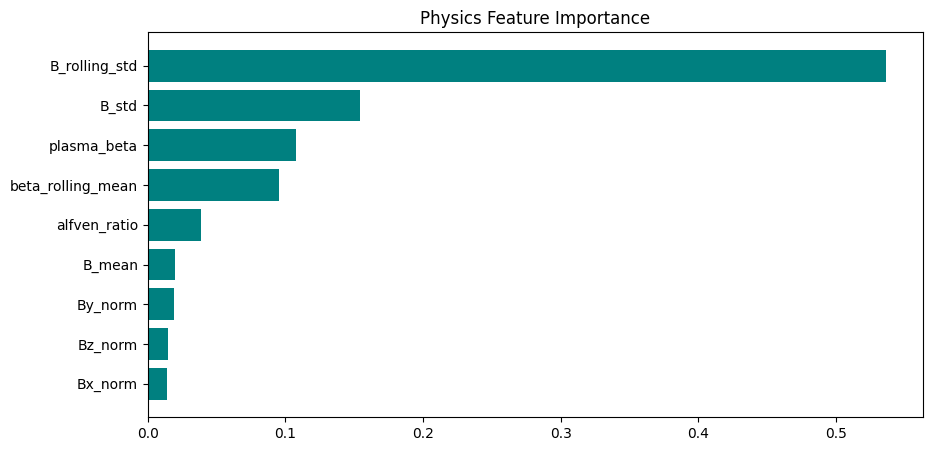

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# --- STEP 1: LOAD & PREPARE ---
df = pd.read_csv("ACE_CS_Preprocessed.csv")

# SAFETY RENAME: This ensures the rest of the script finds the names you want
rename_dict = {'beta': 'plasma_beta', 'Alfven_Ratio': 'alfven_ratio'}
df = df.rename(columns=rename_dict)

# Defining the label
threshold = df['dB_dt'].mean() + (3 * df['dB_dt'].std())
df['Label'] = (df['dB_dt'] > threshold).astype(int)

# --- STEP 1.5: CREATE CONTEXT FEATURES ---
# We use 'plasma_beta' here as you requested
df['B_rolling_std'] = df['B_mean'].rolling(window=3).std()
df['beta_rolling_mean'] = df['plasma_beta'].rolling(window=3).mean()
df['Bx_norm'] = df['Bx'] / df['B_mean']
df['By_norm'] = df['By'] / df['B_mean']
df['Bz_norm'] = df['Bz'] / df['B_mean']

# Drop NaNs created by rolling windows
df = df.dropna(subset=['B_rolling_std', 'beta_rolling_mean']).copy()

# --- STEP 2: SELECT PHYSICS FEATURES ---
# These are the final features the model will learn from
features = [
    'B_mean', 'B_std', 'plasma_beta', 'alfven_ratio',
    'B_rolling_std', 'beta_rolling_mean',
    'Bx_norm', 'By_norm', 'Bz_norm'
]

X = df[features]
y = df['Label']

# --- STEP 3: SPLIT & SCALE ---
split_idx = int(len(df) * 0.7)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- STEP 4: TRAIN THE MODEL ---
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=10,
    class_weight='balanced_subsample',
    random_state=42
)
rf.fit(X_train_scaled, y_train)

# --- STEP 5: EVALUATE WITH THRESHOLD ---
y_probs = rf.predict_proba(X_test_scaled)[:, 1]

# 0.55 is the sweet spot for precision; 0.35 is better for recall.
custom_threshold = 0.55
y_pred = (y_probs >= custom_threshold).astype(int)

print(f"--- Final Report (Threshold: {custom_threshold}) ---")
print(classification_report(y_test, y_pred))

# Plot Importance
importances = rf.feature_importances_
indices = np.argsort(importances)
plt.figure(figsize=(10, 5))
plt.title('Physics Feature Importance')
plt.barh(range(len(indices)), importances[indices], color='teal')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.show()

XGboost

--- XGBOOST FINAL REPORT (Threshold: 0.55) ---
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       648
           1       0.27      0.75      0.40         8

    accuracy                           0.97       656
   macro avg       0.63      0.86      0.69       656
weighted avg       0.99      0.97      0.98       656



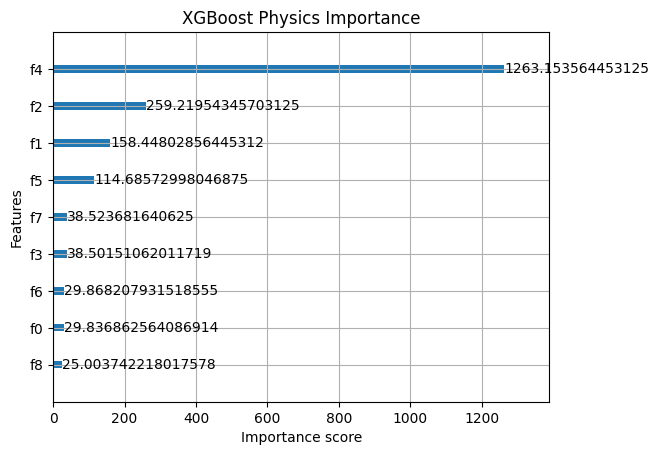

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# --- STEP 1: LOAD & RENAME ---
df = pd.read_csv("ACE_CS_Preprocessed.csv")

# Ensure column names match your specified environment
# If they are already named this way, these lines won't hurt.
rename_dict = {'beta': 'plasma_beta', 'Alfven_Ratio': 'alfven_ratio'}
df = df.rename(columns=rename_dict)

# Re-create the Label (Target)
threshold = df['dB_dt'].mean() + (3 * df['dB_dt'].std())
df['Label'] = (df['dB_dt'] > threshold).astype(int)

# --- STEP 2: FEATURE ENGINEERING (CREATING MISSING COLUMNS) ---
# We must create these BEFORE we try to use them in the model
df['B_rolling_std'] = df['B_mean'].rolling(window=3).std()
df['beta_rolling_mean'] = df['plasma_beta'].rolling(window=3).mean()
df['Bx_norm'] = df['Bx'] / df['B_mean']
df['By_norm'] = df['By'] / df['B_mean']
df['Bz_norm'] = df['Bz'] / df['B_mean']

# Drop the rows with NaNs from the rolling calculations
df = df.dropna(subset=['B_rolling_std', 'beta_rolling_mean']).copy()

# Select the Physics Features
features = [
    'B_mean', 'B_std', 'plasma_beta', 'alfven_ratio',
    'B_rolling_std', 'beta_rolling_mean',
    'Bx_norm', 'By_norm', 'Bz_norm'
]

X = df[features]
y = df['Label']

# --- STEP 3: TIME-SERIES SPLIT & SCALING ---
split_idx = int(len(df) * 0.7)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- STEP 4: CALCULATE SCALE_POS_WEIGHT (Fixing Imbalance) ---
# This ratio tells XGBoost how much more weight to give to the rare 1s.
count_class_0 = (y_train == 0).sum()
count_class_1 = (y_train == 1).sum()

# Safety check for ratio calculation
ratio = count_class_0 / count_class_1 if count_class_1 > 0 else 1

# --- STEP 5: INITIALIZE & TRAIN XGBOOST ---
model_xgb = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=4,                # Slightly deeper than 3 to capture complex patterns
    learning_rate=0.01,
    scale_pos_weight=ratio,     # Crucial for Current Sheet detection
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=10,              # Regularization to prevent overfitting
    early_stopping_rounds=20,   # Stops training if it starts overfitting
    eval_metric='aucpr',        # Best for imbalanced precision-recall
    random_state=42
)

model_xgb.fit(
    X_train_scaled, y_train,
    eval_set=[(X_test_scaled, y_test)],
    verbose=False
)

# --- STEP 6: EVALUATE WITH THRESHOLD ---
y_probs = model_xgb.predict_proba(X_test_scaled)[:, 1]

# Use the same threshold as your Random Forest for a fair comparison
custom_threshold = 0.55
y_pred = (y_probs >= custom_threshold).astype(int)

print(f"--- XGBOOST FINAL REPORT (Threshold: {custom_threshold}) ---")
print(classification_report(y_test, y_pred))

# Plot Feature Importance
xgb.plot_importance(model_xgb, importance_type='gain', max_num_features=10)
plt.title('XGBoost Physics Importance')
plt.show()